
# Extra Trees (Extremely Randomized Trees)

Extra Trees, also known as Extremely Randomized Trees, is an ensemble machine learning algorithm used for both regression and classification tasks.

It belongs to the family of tree-based ensemble methods. Similar to Random Forest, Extra Trees builds multiple decision trees and combines their predictions to produce a final result.

However, Extra Trees introduces additional randomness during the construction of decision trees. Instead of searching for the optimal split threshold for each selected feature, it chooses split thresholds randomly and selects the best among those random splits.

This additional randomization can reduce variance, help prevent overfitting, and improve generalization.

## How Extra Trees Works

1. Selects random subsets of features when building decision trees.
2. Generates random split thresholds for the selected features.
3. Selects the best split among the randomly generated candidates.
4. Repeats the process to construct multiple decision trees.
5. Combines the predictions from all trees.

For classification, predictions are combined through voting or averaged class probabilities.

For regression, predictions are combined by averaging the outputs of individual trees.

## Types of Extra Trees Models

- **Extra Trees Classifier:** Used for classification problems involving categorical target variables.
- **Extra Trees Regressor:** Used for regression problems involving continuous target variables.

## Key Characteristics

- Uses an ensemble of randomized decision trees.
- Introduces more randomness than Random Forest.
- Supports classification and regression.
- Can capture nonlinear relationships.
- Does not generally require feature scaling.
- Can provide feature importance scores.

## Advantages

- Can reduce variance and help limit overfitting.
- Captures complex relationships in data.
- Handles large numbers of numerical features.
- Supports parallel processing.
- Requires relatively little preprocessing.

## Limitations

- Can be less interpretable than a single decision tree.
- Randomization may sometimes reduce predictive accuracy.
- Can require substantial memory when using many trees.
- Feature importance scores can be biased toward certain types of features.

## Extra Trees vs Random Forest

Both algorithms combine multiple decision trees, but they differ in how they choose splits.

Random Forest searches for the best split among candidate thresholds for selected features, whereas Extra Trees introduces additional randomness by choosing random split thresholds.

This makes Extra Trees more randomized during tree construction.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing, load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import (ExtraTreesRegressor,ExtraTreesClassifier)
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score,classification_report,confusion_matrix,ConfusionMatrixDisplay)
import warnings

warnings.filterwarnings('ignore')

## Regression

In [2]:
# load dataset
housing = fetch_california_housing(as_frame=True)

housing_df = housing.frame.copy()

print(housing_df.shape)
housing_df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
housing_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [4]:
housing_df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [5]:
housing_df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

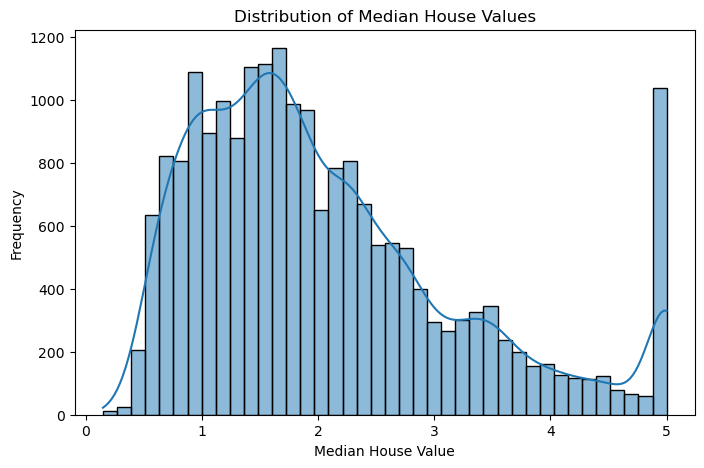

In [6]:
# target distribution

plt.figure(figsize=(8, 5))

sns.histplot(housing_df['MedHouseVal'],bins=40,kde=True)

plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

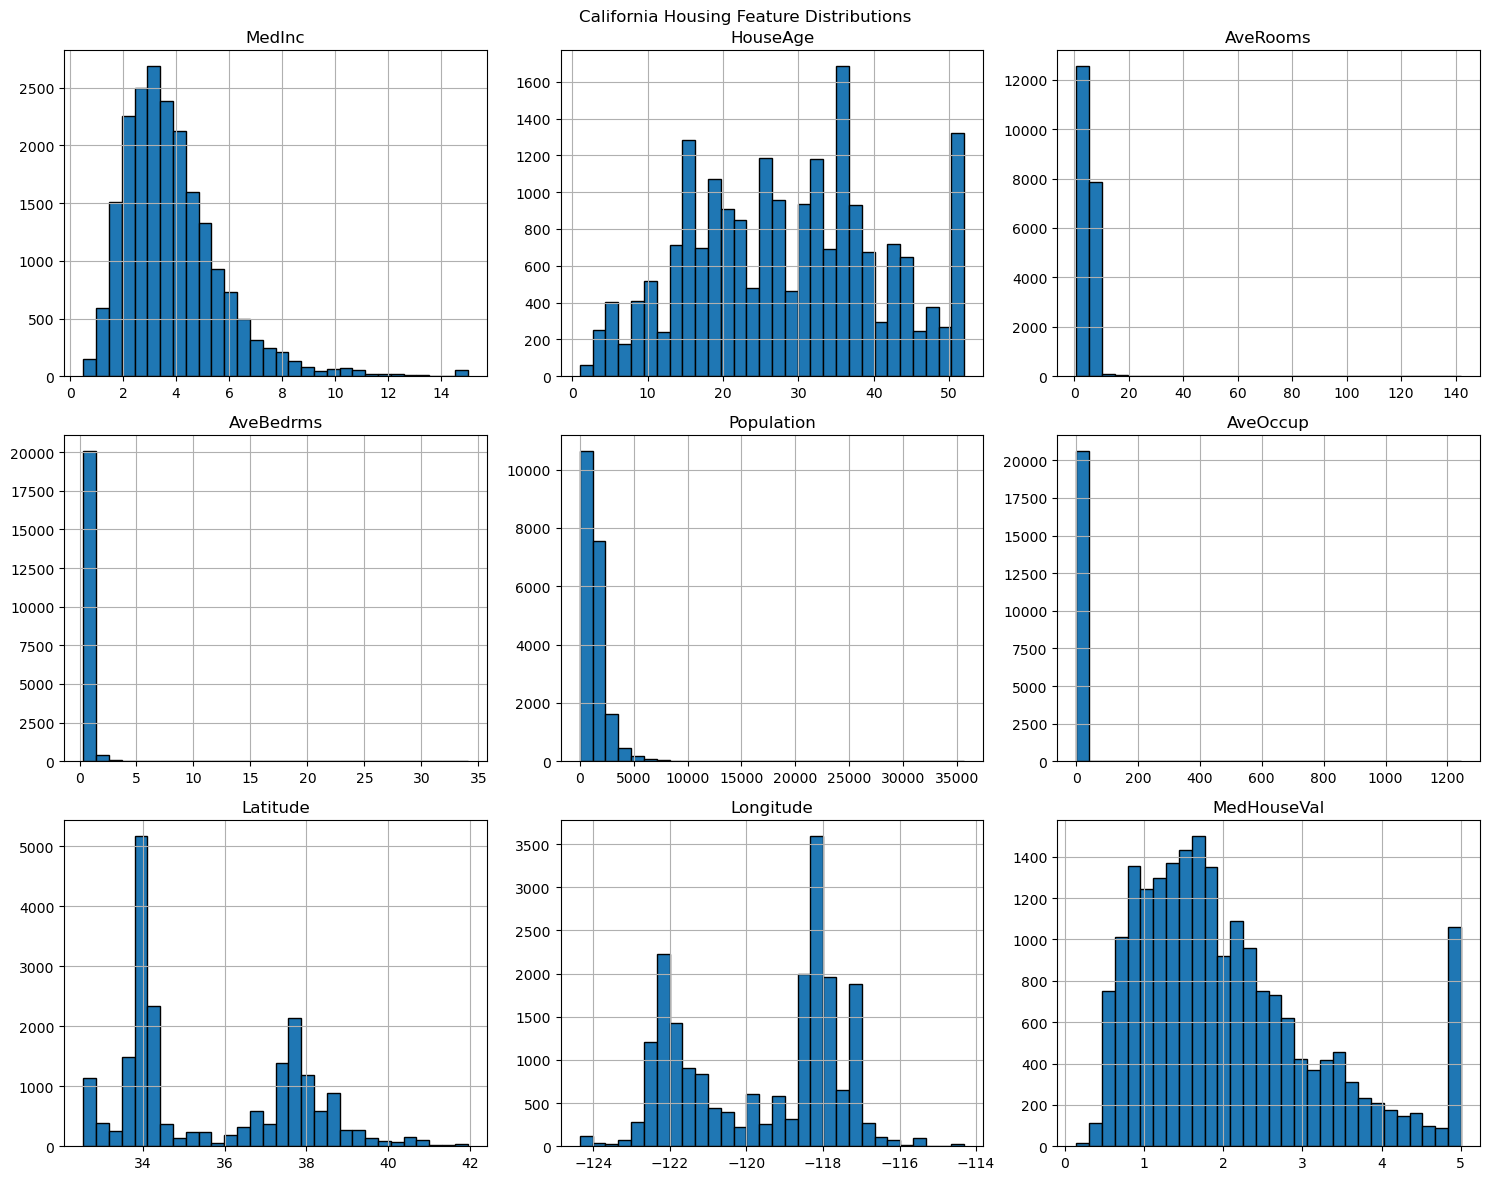

In [7]:
# feature distributions

housing_df.hist(figsize=(15, 12),bins=30,edgecolor='black')

plt.suptitle('California Housing Feature Distributions')
plt.tight_layout()
plt.show()

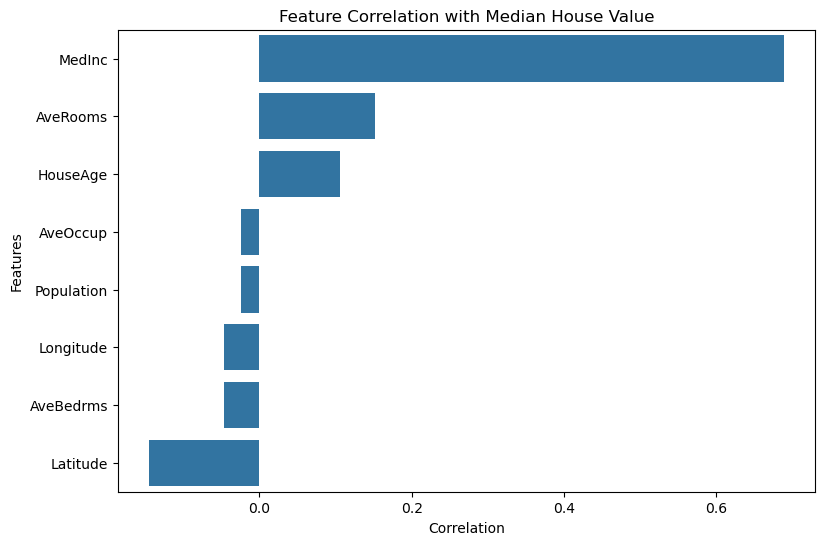

In [8]:
# feature rlship with target

target_corr = housing_df.corr()['MedHouseVal'].drop(
    'MedHouseVal'
).sort_values(ascending=False)

plt.figure(figsize=(9, 6))

sns.barplot(x=target_corr.values,y=target_corr.index)

plt.title('Feature Correlation with Median House Value')
plt.xlabel('Correlation')
plt.ylabel('Features')
plt.show()

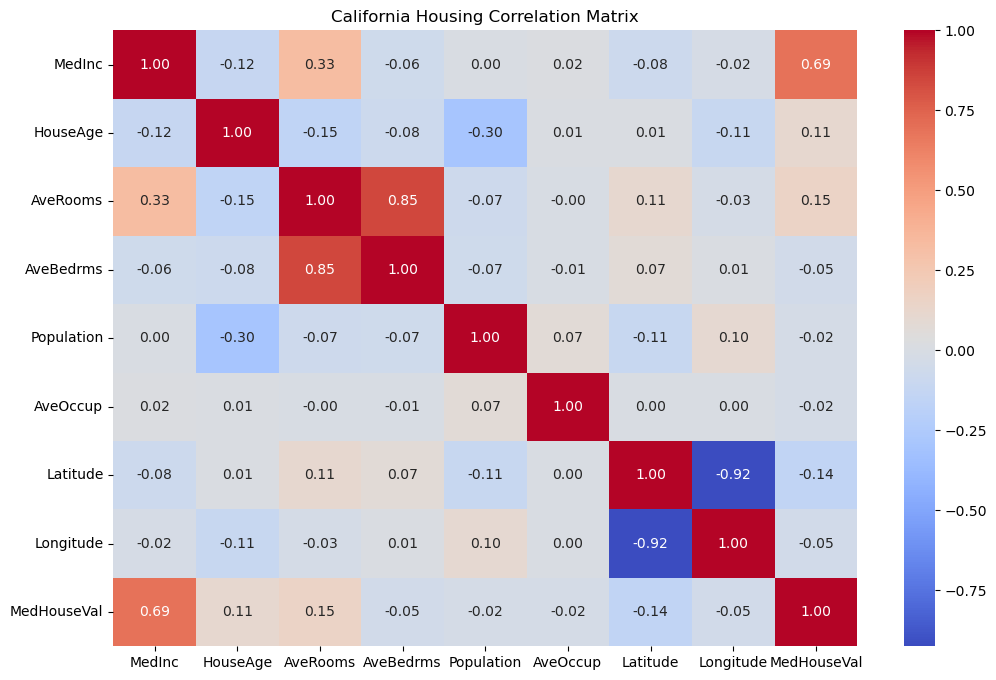

In [9]:
# correlation analysis
plt.figure(figsize=(12, 8))

sns.heatmap(housing_df.corr(),annot=True,cmap='coolwarm',fmt='.2f')

plt.title('California Housing Correlation Matrix')
plt.show()

In [10]:
# Preprocessing

X = housing_df.drop('MedHouseVal', axis=1)
y = housing_df['MedHouseVal']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20640, 8)
Target Shape: (20640,)


In [11]:
# train-test split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 8)
Testing Features: (4128, 8)
Training Target: (16512,)
Testing Target: (4128,)


In [12]:
# Modelling

etr = ExtraTreesRegressor(random_state=42)

etr.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [13]:
# Predictions

y_train_pred = etr.predict(X_train)
y_test_pred = etr.predict(X_test)

print("Training Predictions:", y_train_pred[:10])
print("\nTesting Predictions:", y_test_pred[:10])

Training Predictions: [1.03    3.821   1.726   0.934   0.965   2.648   1.573   5.00001 1.398
 3.156  ]

Testing Predictions: [0.46975   0.76043   4.8886549 2.6495    2.41233   1.8843301 2.25699
 1.67677   2.6138402 4.7916578]


In [14]:
# Evaluation

# Training evaluation
etr_train_mae = mean_absolute_error(y_train, y_train_pred)
etr_train_mse = mean_squared_error(y_train, y_train_pred)
etr_train_rmse = np.sqrt(etr_train_mse)
etr_train_r2 = r2_score(y_train, y_train_pred)

# Testing evaluation
etr_mae = mean_absolute_error(y_test, y_test_pred)
etr_mse = mean_squared_error(y_test, y_test_pred)
etr_rmse = np.sqrt(etr_mse)
etr_r2 = r2_score(y_test, y_test_pred)

print("Training Performance")
print(f"MAE:  {etr_train_mae:.6f}")
print(f"MSE:  {etr_train_mse:.6f}")
print(f"RMSE: {etr_train_rmse:.6f}")
print(f"R2:   {etr_train_r2:.6f}")

print("\nTesting Performance")
print(f"MAE:  {etr_mae:.6f}")
print(f"MSE:  {etr_mse:.6f}")
print(f"RMSE: {etr_rmse:.6f}")
print(f"R2:   {etr_r2:.6f}")


Training Performance
MAE:  0.000000
MSE:  0.000000
RMSE: 0.000000
R2:   1.000000

Testing Performance
MAE:  0.326997
MSE:  0.253904
RMSE: 0.503889
R2:   0.806241


In [15]:
# Actual vs predicted

etr_results = pd.DataFrame({
    'Actual Values': y_test.values,
    'Predicted Values': y_test_pred
})

display(etr_results.head(10))

,Actual Values,Predicted Values
0,0.47700,0.469750
1,0.45800,0.760430
2,5.00001,4.888655
3,2.18600,2.649500
4,2.78000,2.412330
5,1.58700,1.884330
6,1.98200,2.256990
7,1.57500,1.676770
8,3.40000,2.613840
9,4.46600,4.791658


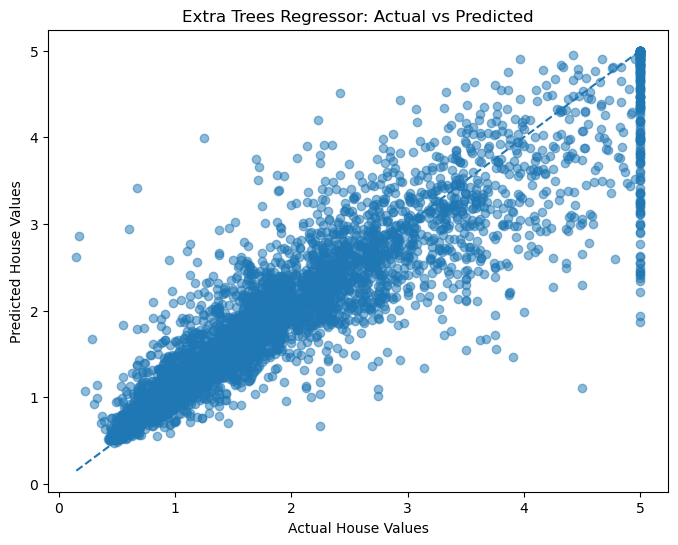

In [16]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test,y_test_pred,alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle='--'
)

plt.title('Extra Trees Regressor: Actual vs Predicted')
plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.show()

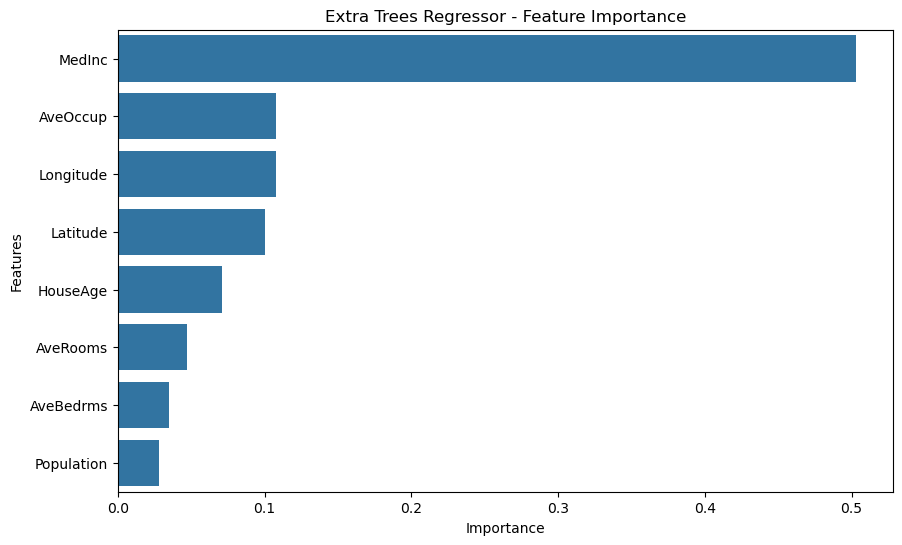

In [17]:
# feature importance

etr_importance = pd.Series(
    etr.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))

sns.barplot(x=etr_importance.values,y=etr_importance.index)
plt.title('Extra Trees Regressor - Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

In [18]:
# Hyperparameter Tuning
etr_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 20, 30],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': [1.0, 0.8]
}
# Gridsearch cv

etr_grid = GridSearchCV(
    estimator=ExtraTreesRegressor(random_state=42, n_jobs=-1),
    param_grid=etr_param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

etr_grid.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,estimator,ExtraTreesReg...ndom_state=42)
,param_grid,"{'max_depth': [None, 20, ...], 'max_features': [1.0, 0.8], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [19]:

print("Best Parameters:", etr_grid.best_params_)
print("Best Cross-Validation RMSE:", 
      np.sqrt(-etr_grid.best_score_))

Best Parameters: {'max_depth': 30, 'max_features': 0.8, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best Cross-Validation RMSE: 0.4936719077469642


In [20]:
# evaluate tuned model
best_etr = etr_grid.best_estimator_

y_tuned_pred = best_etr.predict(X_test)

tuned_mae = mean_absolute_error(y_test, y_tuned_pred)
tuned_mse = mean_squared_error(y_test, y_tuned_pred)
tuned_rmse = np.sqrt(tuned_mse)
tuned_r2 = r2_score(y_test, y_tuned_pred)

print("Tuned Extra Trees Regressor")
print(f"MAE:  {tuned_mae:.6f}")
print(f"MSE:  {tuned_mse:.6f}")
print(f"RMSE: {tuned_rmse:.6f}")
print(f"R2:   {tuned_r2:.6f}")

Tuned Extra Trees Regressor
MAE:  0.318477
MSE:  0.241096
RMSE: 0.491015
R2:   0.816015


In [21]:

etr_comparison = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R2 Score'],
    'Original Model': [
        etr_mae,
        etr_mse,
        etr_rmse,
        etr_r2
    ],
    'Tuned Model': [
        tuned_mae,
        tuned_mse,
        tuned_rmse,
        tuned_r2
    ]
})

display(etr_comparison.round(6))

,Metric,Original Model,Tuned Model
0,MAE,0.326997,0.318477
1,MSE,0.253904,0.241096
2,RMSE,0.503889,0.491015
3,R2 Score,0.806241,0.816015


#### The tuned model achieved better predictive performance, demonstrating that hyperparameter optimization can improve the performance of Extra Trees Regression.

The tuned model was therefore selected as the preferred regressor for this experiment.

## Classification

In [23]:
# load dataset
cancer = load_breast_cancer()

cancer_df = pd.DataFrame(cancer.data,columns=cancer.feature_names)

cancer_df['target'] = cancer.target

print(cancer_df.shape)
cancer_df.head()

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [24]:
cancer_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [25]:
cancer_df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


target
1    357
0    212
Name: count, dtype: int64

Class Labels:
0 = Malignant
1 = Benign


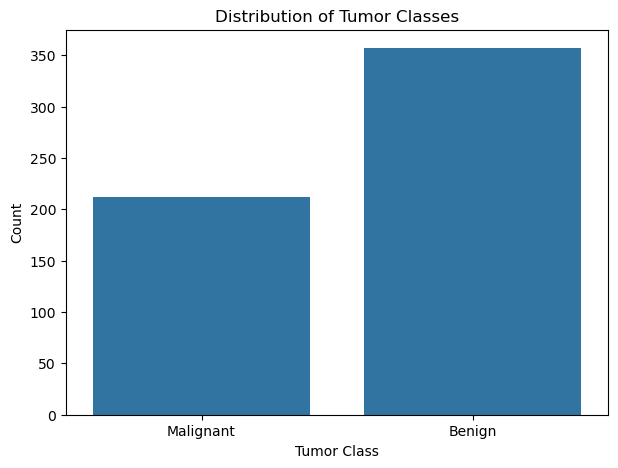

In [26]:
# target distribution

print(cancer_df['target'].value_counts())

print("\nClass Labels:")
print("0 = Malignant")
print("1 = Benign")

plt.figure(figsize=(7, 5))

sns.countplot(data=cancer_df,x='target')

plt.title('Distribution of Tumor Classes')
plt.xlabel('Tumor Class')
plt.ylabel('Count')
plt.xticks([0, 1], ['Malignant', 'Benign'])
plt.show()

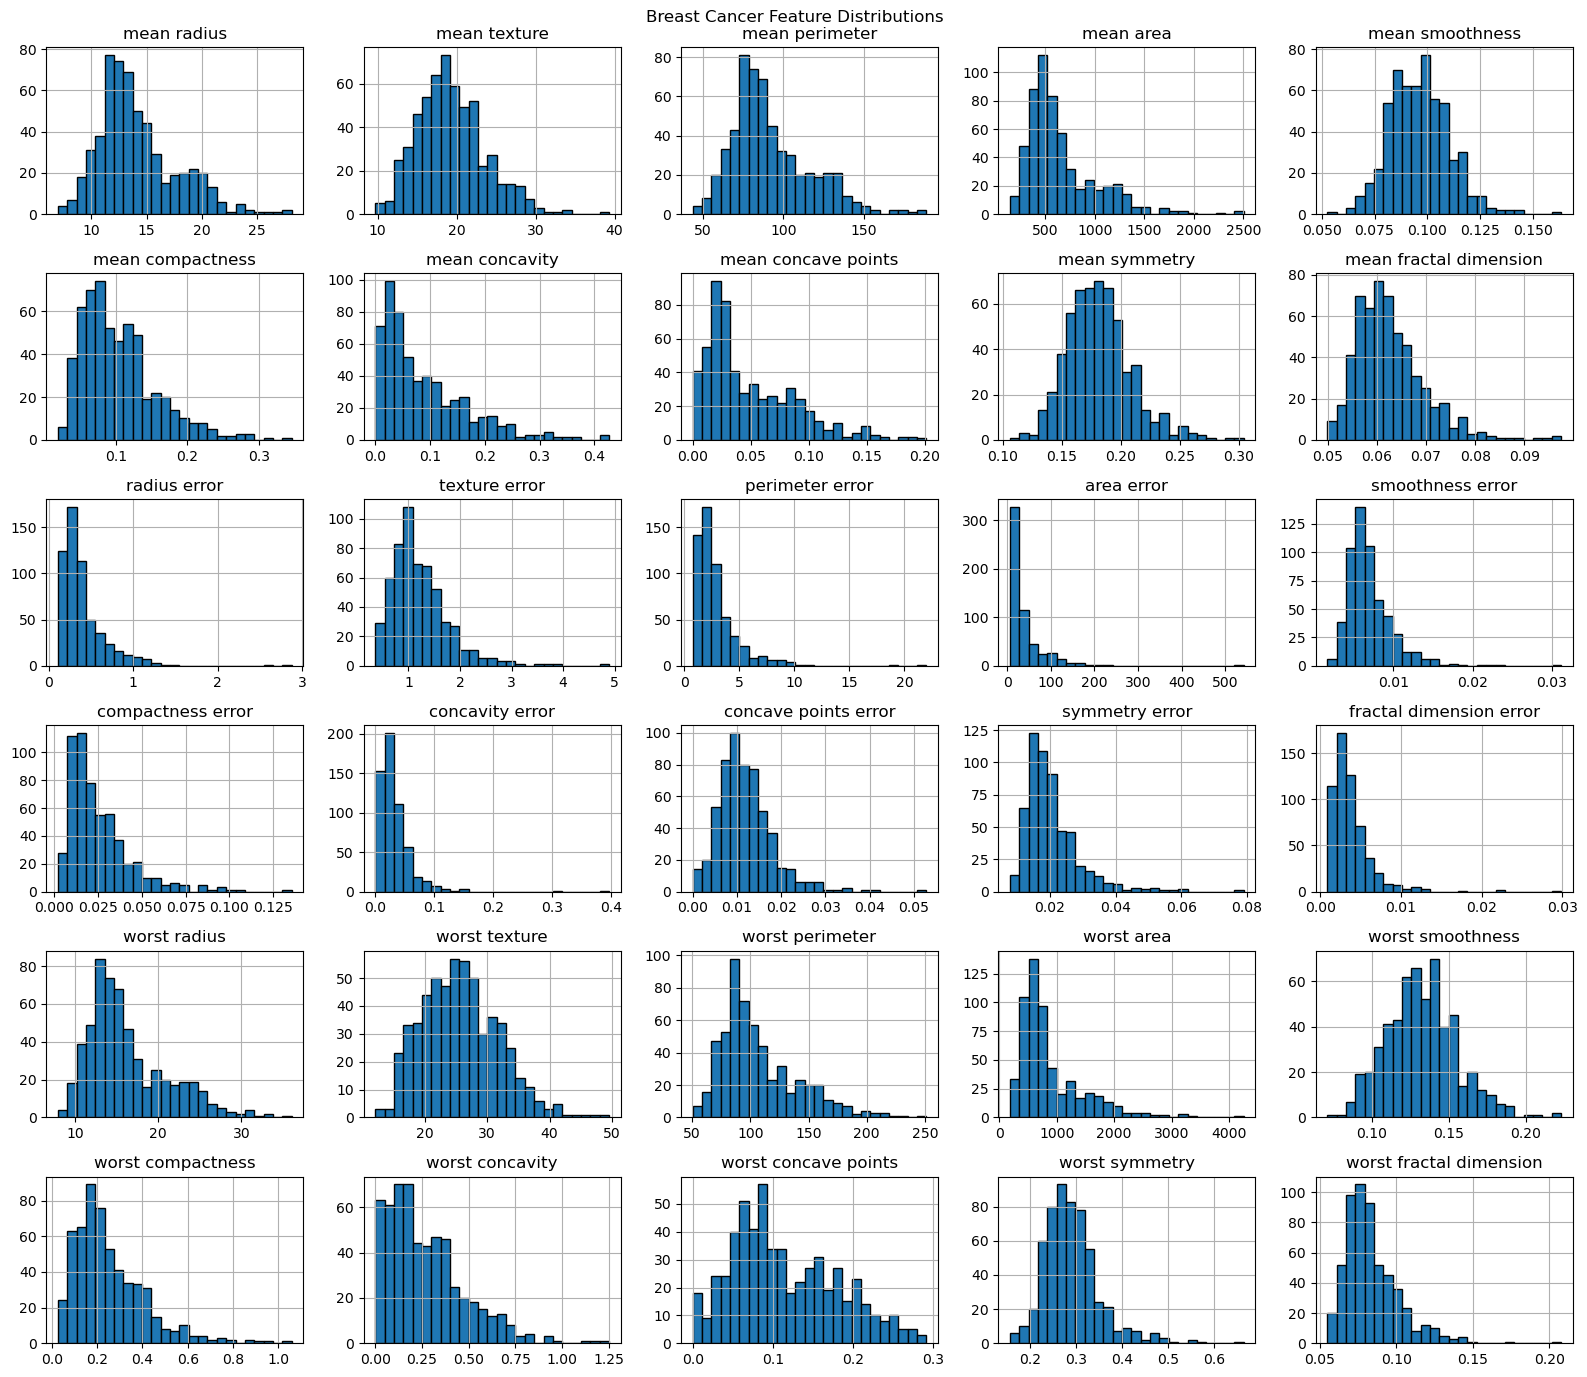

In [27]:
# feature distributions

cancer_df.drop('target', axis=1).hist(figsize=(16, 14),bins=25,edgecolor='black')

plt.suptitle('Breast Cancer Feature Distributions')
plt.tight_layout()
plt.show()

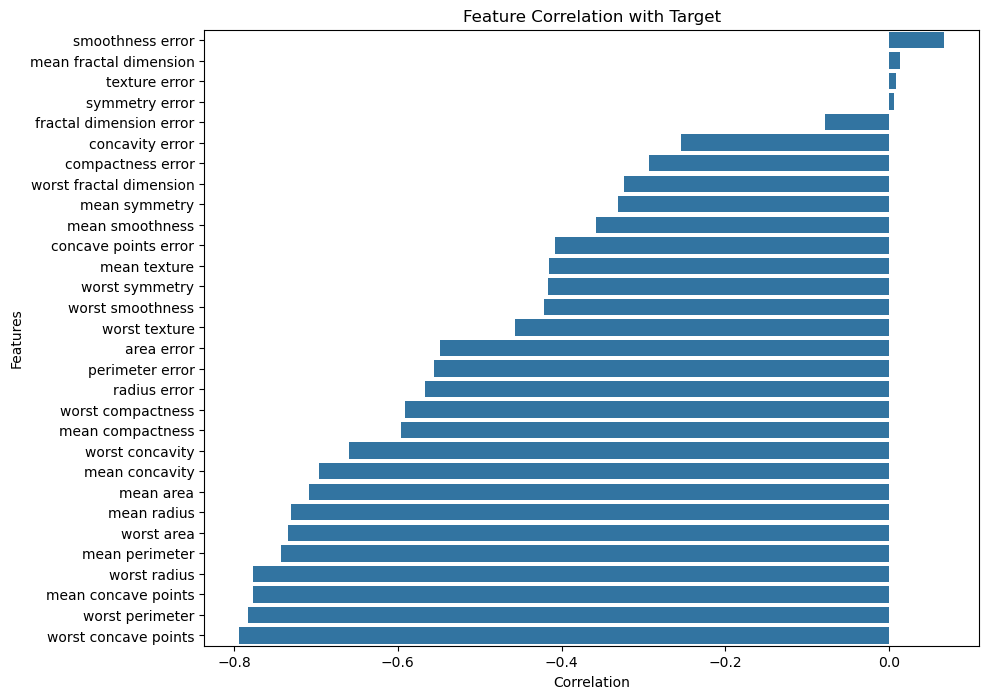

In [28]:
# feature correlation with target

target_corr = cancer_df.corr()['target'].drop(
    'target'
).sort_values(ascending=False)

plt.figure(figsize=(10, 8))

sns.barplot(x=target_corr.values,y=target_corr.index)

plt.title('Feature Correlation with Target')
plt.xlabel('Correlation')
plt.ylabel('Features')
plt.show()

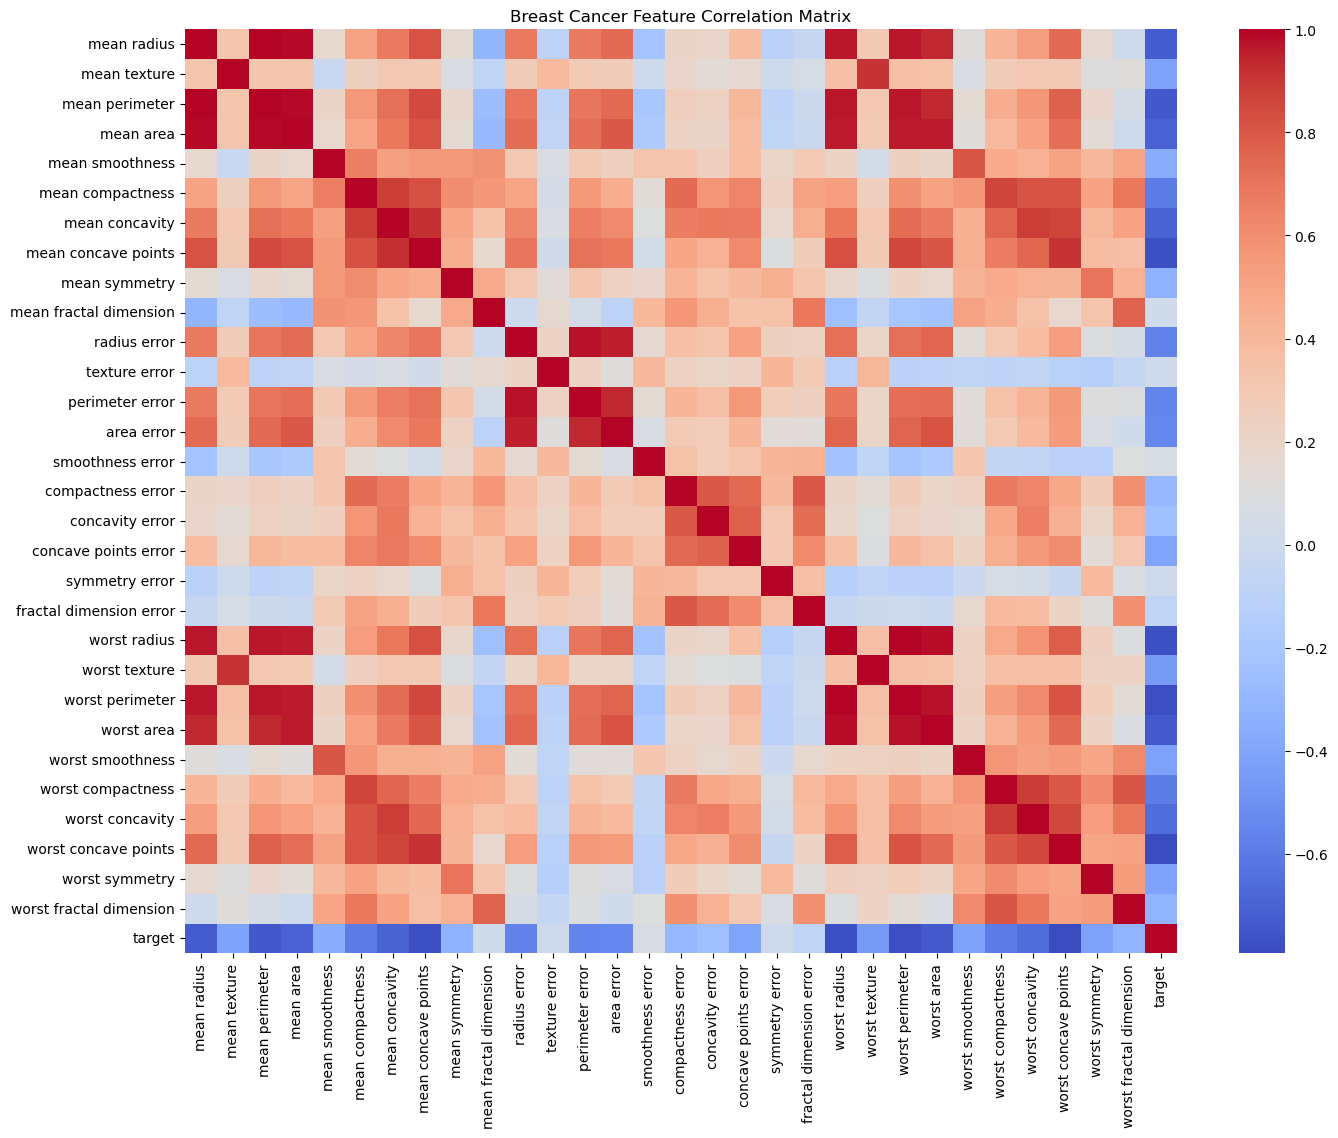

In [29]:
# correlation analysis

plt.figure(figsize=(16, 12))

sns.heatmap(cancer_df.corr(),cmap='coolwarm',annot=False)

plt.title('Breast Cancer Feature Correlation Matrix')
plt.show()

In [30]:
# Preprocessing

X = cancer_df.drop('target', axis=1)
y = cancer_df['target']

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [31]:
# train-test split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (455, 30)
Testing Features: (114, 30)
Training Target: (455,)
Testing Target: (114,)


In [32]:
# Modelling

etc = ExtraTreesClassifier(random_state=42)

etc.fit(X_train, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,False
,oob_score,False


In [33]:
# prediction

y_train_pred = etc.predict(X_train)

y_test_pred = etc.predict(X_test)

y_test_proba = etc.predict_proba(X_test)[:, 1]

print("Training Predictions:", y_train_pred[:10])
print("\nTesting Predictions:", y_test_pred[:10])

Training Predictions: [1 0 1 1 1 1 1 1 1 1]

Testing Predictions: [0 1 0 0 0 1 1 0 0 0]


In [34]:
# Evaluation

etc_accuracy = accuracy_score(y_test, y_test_pred)
etc_precision = precision_score(y_test, y_test_pred)
etc_recall = recall_score(y_test, y_test_pred)
etc_f1 = f1_score(y_test, y_test_pred)
etc_roc_auc = roc_auc_score(y_test, y_test_proba)

print(f"Accuracy:  {etc_accuracy:.6f}")
print(f"Precision: {etc_precision:.6f}")
print(f"Recall:    {etc_recall:.6f}")
print(f"F1 Score:  {etc_f1:.6f}")
print(f"ROC-AUC:   {etc_roc_auc:.6f}")

Accuracy:  0.956140
Precision: 0.958904
Recall:    0.972222
F1 Score:  0.965517
ROC-AUC:   0.992725


In [35]:
# training vs testing accuracy

etc_train_accuracy = accuracy_score(y_train, y_train_pred)

print(f"Training Accuracy: {etc_train_accuracy:.6f}")
print(f"Testing Accuracy:  {etc_accuracy:.6f}")

Training Accuracy: 1.000000
Testing Accuracy:  0.956140


In [36]:
# classification report

print(classification_report(y_test,y_test_pred,target_names=['Malignant', 'Benign']))

              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



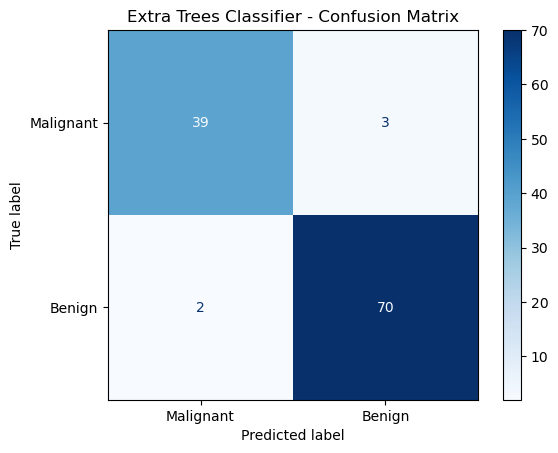

In [37]:
# confusion matrix

cm_etc = confusion_matrix(y_test, y_test_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_etc,display_labels=['Malignant', 'Benign'])

disp.plot(cmap='Blues')
plt.title('Extra Trees Classifier - Confusion Matrix')
plt.show()

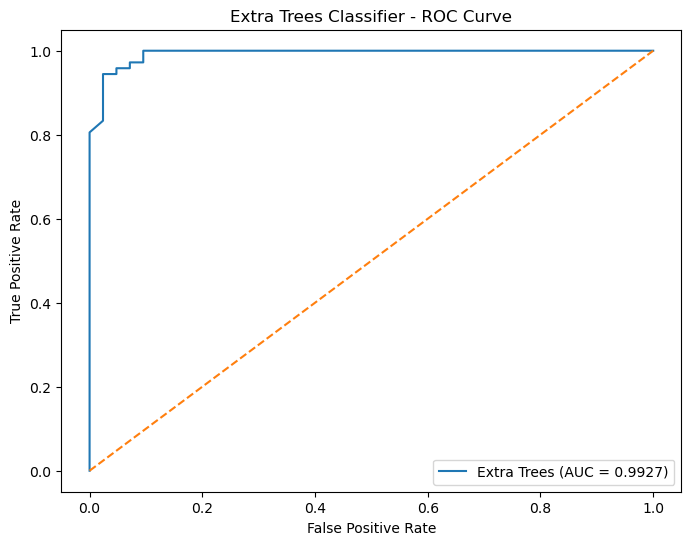

In [39]:
# ROC Curve
from sklearn.metrics import roc_curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr,tpr,label=f'Extra Trees (AUC = {etc_roc_auc:.4f})')

plt.plot([0, 1], [0, 1], linestyle='--')

plt.title('Extra Trees Classifier - ROC Curve')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

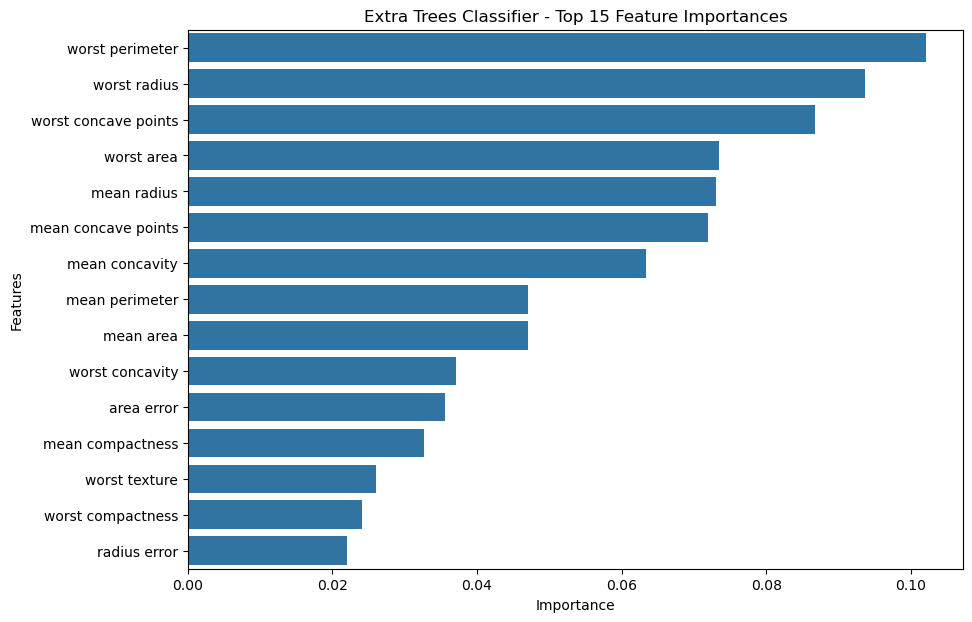

In [40]:
# feature importance

etc_importance = pd.Series(
    etc.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

plt.figure(figsize=(10, 7))

sns.barplot(x=etc_importance.values[:15],y=etc_importance.index[:15])

plt.title('Extra Trees Classifier - Top 15 Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Features')
plt.show()

In [41]:
# Actual vs predicted

etc_results = pd.DataFrame({
    'Actual Category': y_test.values,
    'Predicted Category': y_test_pred
})

display(etc_results.head(10))

,Actual Category,Predicted Category
0,0,0
1,1,1
2,0,0
3,1,0
4,0,0
5,1,1
6,1,1
7,0,0
8,0,0
9,0,0


In [44]:
# Hyperparameter Tuning
etc_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'max_features': ['sqrt', 1.0]
}

etc_grid = GridSearchCV(
    estimator=ExtraTreesClassifier(random_state=42, n_jobs=-1),
    param_grid=etc_param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

etc_grid.fit(X_train, y_train)

Fitting 5 folds for each of 48 candidates, totalling 240 fits


,estimator,ExtraTreesCla...ndom_state=42)
,param_grid,"{'max_depth': [None, 10, ...], 'max_features': ['sqrt', 1.0], 'min_samples_leaf': [1, 2], 'min_samples_split': [2, 5], ...}"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,100


In [45]:
print("Best Parameters:", etc_grid.best_params_)
print("Best Cross-Validation Score:", etc_grid.best_score_)

Best Parameters: {'max_depth': None, 'max_features': 1.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-Validation Score: 0.9824561403508772


In [46]:
# tuned prediction
best_etc = etc_grid.best_estimator_

y_tuned_pred = best_etc.predict(X_test)
y_tuned_proba = best_etc.predict_proba(X_test)[:, 1]

y_tuned_train_pred = best_etc.predict(X_train)

In [47]:
# evaluate tuned model
tuned_accuracy = accuracy_score(y_test, y_tuned_pred)
tuned_precision = precision_score(y_test, y_tuned_pred)
tuned_recall = recall_score(y_test, y_tuned_pred)
tuned_f1 = f1_score(y_test, y_tuned_pred)
tuned_roc_auc = roc_auc_score(y_test, y_tuned_proba)

print("Tuned Training Accuracy:", accuracy_score(y_train, y_tuned_train_pred))
print("Tuned Testing Accuracy:", tuned_accuracy)
print("Precision:", tuned_precision)
print("Recall:", tuned_recall)
print("F1 Score:", tuned_f1)
print("ROC-AUC:", tuned_roc_auc)

Tuned Training Accuracy: 1.0
Tuned Testing Accuracy: 0.956140350877193
Precision: 0.958904109589041
Recall: 0.9722222222222222
F1 Score: 0.9655172413793104
ROC-AUC: 0.9958664021164022


In [48]:
print(classification_report(y_test,y_tuned_pred,target_names=['Malignant', 'Benign']))

              precision    recall  f1-score   support

   Malignant       0.95      0.93      0.94        42
      Benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



In [49]:
print("Malignant Precision:",
      precision_score(y_test, y_tuned_pred, pos_label=0))

print("Malignant Recall:",
      recall_score(y_test, y_tuned_pred, pos_label=0))

print("Malignant F1 Score:",
      f1_score(y_test, y_tuned_pred, pos_label=0))

Malignant Precision: 0.9512195121951219
Malignant Recall: 0.9285714285714286
Malignant F1 Score: 0.9397590361445783


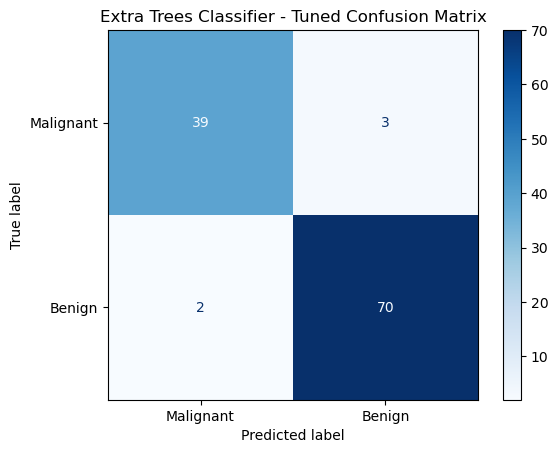

In [50]:
# tuned confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test,y_tuned_pred,display_labels=['Malignant', 'Benign'],cmap='Blues')

plt.title("Extra Trees Classifier - Tuned Confusion Matrix")
plt.show()

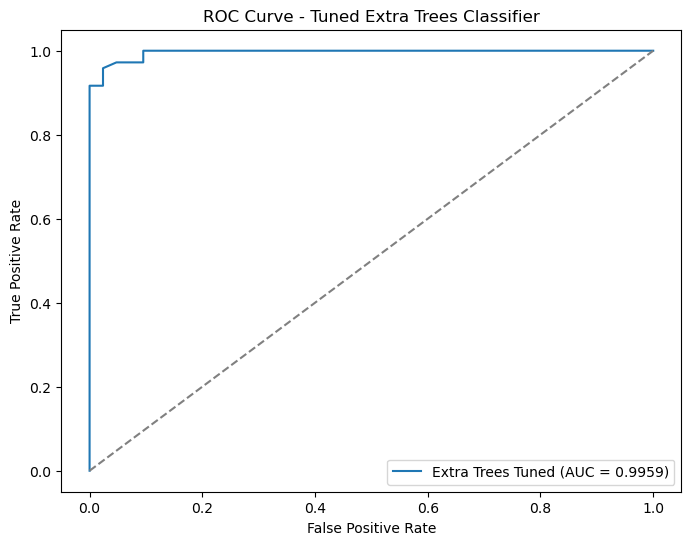

In [51]:
# tuned ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_tuned_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Extra Trees Tuned (AUC = {tuned_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='grey')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Extra Trees Classifier")
plt.legend()
plt.show()